# Chapitre 6 - Exercices 6.1 à 6.6

Ce notebook traite les six premiers exercices du chapitre 6, centrés sur le choix
d'une clé de partitionnement et sur le rééquilibrage :

- **6.1** : choisir une clé de partitionnement pour trois applications (raisonnement
  et simulation) ;
- **6.2** : le hachage ne garantit l'équilibre qu'en moyenne, « balles dans des
  urnes » (calcul et simulation) ;
- **6.3** : modulo N, nombre fixe de partitions et anneau à jetons : clés déplacées
  et nombre de jetons par nœud (démonstration et vérification) ;
- **6.4** : dimensionner un nombre fixe de partitions pour un jeu de données qui
  croît d'un facteur 100 (calcul) ;
- **6.5** : partitionnement dynamique avec fusion des petites partitions, et le
  piège de l'oscillation (mini-lab) ;
- **6.6** : éclater une clé chaude par salage : combien de suffixes, et que faire
  des lectures ? (calcul et simulation).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 6.1 : choisir une clé de partitionnement

**Énoncé.** Pour chacune des trois applications suivantes, on dispose de 8
partitions. Proposer une clé de partitionnement et un schéma (par plage
de clés ou par hachage), en justifiant par les requêtes à servir.

1. **Capteurs.** 500 capteurs envoient chacun une mesure toutes les 10 minutes. Requêtes :
   (a) « toutes les mesures de tous les capteurs entre 10 h et 11 h hier » ; (b)
   « l'historique complet du capteur 42 ». On compare trois clés : l'horodatage seul (par
   plage, une partition par jour), le couple (capteur, horodatage) par plage, et le
   couple (capteur, horodatage) avec hachage du seul identifiant de capteur.
2. **Commandes d'un site marchand.** Requêtes : afficher une commande ; lister les
   commandes d'un client. Clé : identifiant de commande haché, ou identifiant de client
   haché ?
3. **Messages d'un réseau social**, clé = identifiant de l'auteur hachée. La popularité
   des comptes suit une loi de Zipf. La répartition des **lectures** est-elle équitable ?

Vérifier chaque réponse en mesurant le déséquilibre (charge maximale / charge moyenne)
et le nombre de partitions qu'une requête doit interroger.

**Rappels.** Par plage de clés, les clés voisines sont ensemble : les requêtes de plage
sont efficaces mais des écritures sur des clés voisines (horodatages) créent un point
chaud. Par hachage, la charge s'étale mais l'ordre est perdu ; seule la partie hachée de
la clé décide de la partition, le reste peut servir à trier (cours 1, sections
*Partitioning by Key Range* et
*Partitioning by Hash of Key*). Hacher ne règle pas
le cas d'une clé très demandée (cours 3, section *Skewed Workloads and Relieving Hot
Spots*).

**Solution.**

*1. Capteurs.* Avec l'horodatage seul, toutes les écritures d'une journée vont dans
la même partition : déséquilibre en écriture égal à 8 (une partition travaille, sept
dorment). La requête (a) est idéale (une seule partition, un parcours de plage) ; la
requête (b) touche les 8 partitions. Avec (capteur, horodatage), les écritures
s'étalent, (b) devient un parcours de plage dans une seule partition, mais (a) exige
**une requête de plage par capteur**, soit 500 requêtes réparties sur toutes les
partitions. Comme on écrit en continu et qu'on lit l'historique d'un capteur, c'est
le bon choix ; la requête (a), plus rare, se paie. Par plage ou par hachage de
l'identifiant de capteur, les deux variantes se valent ici ; la plage donne un meilleur
équilibre parce que les identifiants sont denses et de charge égale, le hachage de 500
valeurs seulement laisse un déséquilibre visible (15 %, voir l'exercice 6.2).

*2. Commandes.* Hacher l'identifiant de **client** place toutes les commandes d'un client
ensemble : « lister les commandes d'un client » touche une partition, et l'affichage
d'une commande aussi pourvu que l'identifiant de commande contienne celui du client (clé
composée (client, commande), le client servant de clé de partitionnement et la commande
de clé de tri). Hacher l'identifiant de commande équilibre parfaitement mais oblige à
interroger toutes les partitions (ou un index secondaire global) pour la liste d'un
client.

*3. Réseau social.* Le hachage répartit les **comptes** équitablement, pas la
**charge** : les lectures d'un compte célèbre arrivent toutes sur
la même partition. Si le compte le plus lu reçoit une part des lectures supérieure à 1/8, aucun
schéma de partitionnement par auteur ne peut équilibrer ; il faut des répliques, un cache,
ou un traitement spécial des clés chaudes.

**Vérification.** Huit jours de mesures simulées (`P.sensor_readings`), puis 100 000
comptes avec des lectures en loi de Zipf d'exposant 1,1.

In [2]:
N = 8
sid, t = P.sensor_readings(500, 8 * 86400, 1 / 600, seed=1)
jour = (t // 86400).astype(int)
schemas = {
    "horodatage (plage, 1 par jour)": jour,
    "(capteur, horodatage) par plage": (sid * N) // 500,
    "(capteur, horodatage), capteur haché": (P.mix64(sid) % np.uint64(N)).astype(int),
}
rows = []
for nom, sh in schemas.items():
    imb = np.mean([P.imbalance(P.shard_loads(sh[jour == d], N)) for d in range(8)])
    req_a = len(np.unique(sh[(jour == 6) & ((t % 86400) // 3600 == 10)]))
    req_b = len(np.unique(sh[sid == 42]))
    rows.append({"clé": nom, "déséquilibre en écriture (par jour)": imb,
                 "partitions lues, requête (a)": req_a,
                 "requêtes de plage, (a)": 1 if nom.startswith("horo") else 500,
                 "partitions lues, requête (b)": req_b})
tab = pd.DataFrame(rows).set_index("clé")
print(f"{fmt(len(sid))} mesures simulées")
tab

576 025 mesures simulées


,déséquilibre en écriture (par jour),"partitions lues, requête (a)","requêtes de plage, (a)","partitions lues, requête (b)"
clé,,,,
"horodatage (plage, 1 par jour)",8.000,1,1,8
"(capteur, horodatage) par plage",1.019,8,500,1
"(capteur, horodatage), capteur haché",1.154,8,500,1


In [3]:
cmd_client = rng.integers(0, 20_000, 200_000)          # client de chaque commande
cmd_id = np.arange(cmd_client.size)
par_cmd = (P.mix64(cmd_id) % np.uint64(N)).astype(int)
par_cli = (P.mix64(cmd_client) % np.uint64(N)).astype(int)
clients = rng.choice(20_000, 500, replace=False)
lues_cmd = np.mean([len(np.unique(par_cmd[cmd_client == c])) for c in clients])
lues_cli = np.mean([len(np.unique(par_cli[cmd_client == c])) for c in clients])
print(f"commandes par client : {cmd_client.size / 20_000:.0f} en moyenne")
print(f"lister les commandes d'un client : {lues_cmd:.2f} partitions lues (clé = commande) "
      f"contre {lues_cli:.2f} (clé = client)")
print(f"déséquilibre en volume : {P.imbalance(P.shard_loads(par_cmd, N)):.3f} (commande), "
      f"{P.imbalance(P.shard_loads(par_cli, N)):.3f} (client)")

commandes par client : 10 en moyenne
lister les commandes d'un client : 5.75 partitions lues (clé = commande) contre 1.00 (clé = client)
déséquilibre en volume : 1.008 (commande), 1.028 (client)


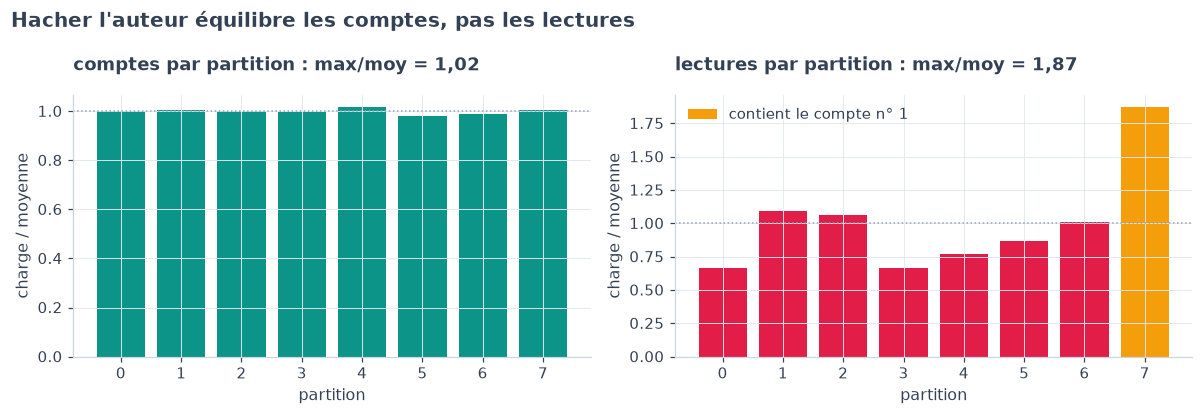

part des lectures du compte le plus populaire : 13.4% (1/8 = 12,5 %)


In [4]:
n_comptes = 100_000
lectures = P.zipf_requests(n_comptes, 1_000_000, s=1.1, seed=2)
part_compte = (P.mix64(np.arange(n_comptes)) % np.uint64(N)).astype(int)
charge = P.shard_loads(part_compte[lectures], N)
comptes = P.shard_loads(part_compte, N)
part_top = np.mean(lectures == 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, val, titre, c in [(axes[0], comptes, "comptes par partition", TEAL),
                          (axes[1], charge, "lectures par partition", ROSE)]:
    ax.bar(range(N), val / val.mean(), color=c)
    ax.axhline(1, color=GRAY, ls=":", lw=1)
    ax.set_xlabel("partition"); ax.set_ylabel("charge / moyenne")
    ax.set_title(titre + f" : max/moy = {P.imbalance(val):.2f}".replace(".", ","))
axes[1].bar(part_compte[0], charge[part_compte[0]] / charge.mean(), color=AMBER, label="contient le compte n° 1")
axes[1].legend(loc="upper left")
finish(fig, "Hacher l'auteur équilibre les comptes, pas les lectures")
plt.show()
print(f"part des lectures du compte le plus populaire : {part_top:.1%} (1/8 = 12,5 %)")

Les chiffres confirment le raisonnement. Pour les capteurs, l'horodatage seul donne un
déséquilibre de 8 (toute la journée sur une partition) ; les deux clés composées
l'éliminent, la plage sur l'identifiant de capteur étant presque parfaite et le hachage
de 500 identifiants laissant un écart de quelques pour cent à une quinzaine de pour cent,
que l'exercice suivant explique. La requête (a) touche alors toutes les
partitions et coûte 500 parcours de plage, la requête (b) une seule. Pour les commandes, la clé
« client » ramène la liste d'un client à une seule partition contre 5,75 en moyenne avec la
clé « commande » (10 commandes par client, réparties au hasard sur 8). Pour le réseau social, le compte le plus lu attire à lui seul 13 %
des lectures : sa partition porte largement plus que la moyenne, quel que soit le
hachage.

> **À retenir.** On choisit la clé de partitionnement d'après les **requêtes** : la
> requête fréquente doit toucher une seule partition, les écritures doivent s'étaler.
> Une clé composée (clé de partitionnement, clé de tri) concilie souvent les deux. Et
> aucun schéma ne répartit une charge concentrée sur une seule clé.

## Exercice 6.2 : le hachage n'équilibre qu'en moyenne

**Énoncé.** On hache $m$ clés de charge égale dans $n$ partitions : chaque
partition reçoit en moyenne $\lambda = m/n$ clés.

1. Quelle loi suit le nombre de clés d'une partition ? Donner son écart-type relatif.
2. Le maximum de $n$ telles variables vaut environ $\lambda + z_n \sqrt{\lambda}$, avec
   $z_n \approx \sqrt{2 \ln n}$. En déduire le nombre de clés par partition nécessaire
   pour que le déséquilibre max/moyenne reste sous 1,1, pour $n = 10$, 100 et 1 000.
3. Vérifier par simulation. Que dire d'un système qui ne place que quelques dizaines
   de clés (ou de capteurs, ou de clients) par partition ?

**Rappels.** Une bonne fonction de hachage rend les positions des clés indépendantes et
uniformes (cours 1, section *Partitioning by Hash of Key*) : le
placement des clés est alors exactement l'expérience des « balles jetées au hasard dans
des urnes ».

**Solution.**

*1.* Chaque clé tombe dans une partition donnée avec probabilité $1/n$, indépendamment :
le nombre de clés suit une loi binomiale $\mathcal{B}(m, 1/n)$, quasi poissonnienne de
paramètre $\lambda$. Son écart-type vaut $\sqrt{\lambda}$, soit un écart **relatif** de
$1/\sqrt{\lambda}$ : 100 clés par partition donnent déjà ±10 % d'une partition à l'autre.

*2.* On veut $z_n\sqrt{\lambda} \le 0{,}1\,\lambda$, soit $\lambda \ge (z_n / 0{,}1)^2 =
200 \ln n$ : environ **460** clés par partition pour $n = 10$, **920** pour $n = 100$,
**1 380** pour $n = 1\,000$. L'approximation $\sqrt{2 \ln n}$ surestime un peu le
maximum pour les petits $n$ ; une version plus fine retranche
$(\ln \ln n + \ln 4\pi) / (2\sqrt{2\ln n})$, ce qui abaisse les seuils (environ 190, 560
et 970).

*3.* Avec quelques dizaines de clés par partition, l'écart dépasse 50 % :
la partition la plus chargée porte une fois et demie la moyenne. C'est le cas des 500
capteurs de l'exercice 6.1 (62 par partition). Le hachage n'est un bon égaliseur que
s'il y a **beaucoup** de clés de poids comparables.

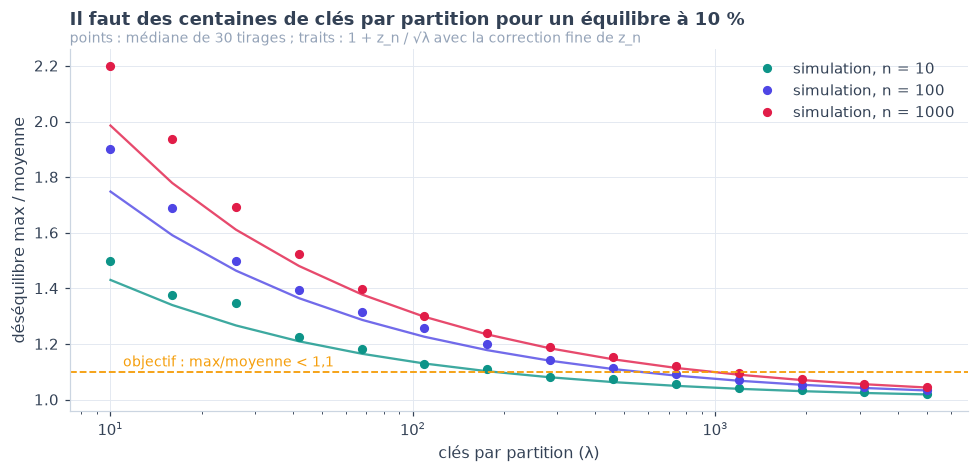

,seuil 200 ln n,seuil affiné,déséquilibre simulé à λ = 1000
n,,,
10,460.517,185.484,1.047
100,921.034,559.916,1.077
1000,1381.551,971.238,1.104


In [5]:
def z_simple(n):
    return math.sqrt(2 * math.log(n))

def z_fin(n):
    z = z_simple(n)
    return z - (math.log(math.log(n)) + math.log(4 * math.pi)) / (2 * z)

lams = np.unique(np.round(np.logspace(1, 3.7, 14)).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.4))
rows = []
for n, c in [(10, TEAL), (100, INDIGO), (1000, ROSE)]:
    sim = [np.median([(lambda x: x.max() / x.mean())(np.bincount(rng.integers(0, n, lam * n), minlength=n))
                      for _ in range(30)]) for lam in lams]
    ax.plot(lams, sim, "o", color=c, ms=5, label=f"simulation, n = {n}")
    ax.plot(lams, 1 + z_fin(n) / np.sqrt(lams), color=c, lw=1.5, alpha=0.8)
    rows.append({"n": n, "seuil 200 ln n": 200 * math.log(n), "seuil affiné": (z_fin(n) / 0.1) ** 2,
                 "déséquilibre simulé à λ = 1000": np.median([(lambda x: x.max() / x.mean())(
                     np.bincount(rng.integers(0, n, 1000 * n), minlength=n)) for _ in range(30)])})
ax.axhline(1.1, color=AMBER, ls="--", lw=1.2)
ax.text(11, 1.12, "objectif : max/moyenne < 1,1", color=AMBER, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("clés par partition (λ)")
ax.set_ylabel("déséquilibre max / moyenne")
ax.set_title("Il faut des centaines de clés par partition pour un équilibre à 10 %")
subtitle(ax, "points : médiane de 30 tirages ; traits : 1 + z_n / √λ avec la correction fine de z_n")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("n").round(3)

La formule affinée suit les points simulés de près dès une centaine de clés par
partition (en dessous, la loi de Poisson est asymétrique et le maximum dépasse un peu la
formule), et les seuils se lisent sur la figure :
à λ = 1 000, le déséquilibre reste sous 1,1 pour n = 10 et n = 100, et l'atteint tout juste
pour n = 1 000 (1,10), conformément au seuil affiné d'environ 970 clés. Le déséquilibre décroît comme $1/\sqrt{\lambda}$ : pour le diviser par
deux, il faut quatre fois plus de clés par partition.

> **À retenir.** Hacher $m$ clés dans $n$ partitions laisse un écart relatif de l'ordre
> de $\sqrt{2\ln n / \lambda}$ entre la partition la plus chargée et la moyenne. Avec peu de
> clés par partition, ou des clés de poids très inégaux, le hasard seul crée des points
> chauds.

## Exercice 6.3 : combien de clés bougent, et combien de jetons par nœud ?

**Énoncé.**

1. Avec l'affectation « haché mod N », montrer que passer de $N$ à $N+1$ nœuds déplace
   une fraction $N/(N+1)$ des clés. Quelle est la fraction minimale à déplacer pour
   rétablir l'équilibre ?
2. Avec un anneau de hachage où chacun des $n$ nœuds tire $v$ jetons au hasard, la part
   de l'anneau possédée par un nœud est la somme de $v$ arcs. Montrer que son écart-type
   relatif vaut environ $1/\sqrt{v}$. Combien de jetons faut-il pour que la part d'un nœud
   s'écarte typiquement de moins de 10 % de $1/n$ ?
3. Vérifier ces deux résultats avec `P.mod_n_assign`, `P.FixedShardCluster` et
   `P.HashRing`.

**Rappels.** Cours 2 (section *Rebalancing Partitions*) :
l'affectation modulo N est la mauvaise façon de faire ; un nombre fixe de
partitions ne déplace que des partitions entières ; l'anneau à jetons aléatoires
(partitionnement proportionnel au nombre de nœuds, à la Cassandra)
découpe des plages existantes pour le nouveau nœud.

**Solution.**

*1.* Prenons le haché $h$ uniforme sur $[0, N(N+1))$ (un multiple commun de $N$ et
$N+1$ ; le cas général s'en déduit à une erreur négligeable près). La clé reste en place
si $h \bmod N = h \bmod (N+1) = r$. Par le théorème des restes chinois ($N$ et $N+1$ sont
premiers entre eux), cela équivaut à $h \equiv r \pmod{N(N+1)}$, donc $h = r$ avec
$0 \le r < N$ : seules $N$ valeurs sur $N(N+1)$ restent, une fraction $1/(N+1)$. La
fraction déplacée vaut donc $N/(N+1)$ : 75 % de 3 à 4 nœuds, 91 % de 10 à 11. Or le
minimum est l'inverse : le nouveau nœud doit recevoir sa part, $1/(N+1)$, et rien
d'autre n'a besoin de bouger.

*2.* Les $nv$ jetons uniformes découpent l'anneau en arcs de longueur quasi
exponentielle de moyenne $1/(nv)$ et de même écart-type. La part d'un nœud est la somme
de ses $v$ arcs (presque indépendants) : moyenne $v/(nv) = 1/n$, écart-type
$\sqrt{v}/(nv)$, soit un écart **relatif** de $1/\sqrt{v}$. Pour descendre sous 10 %, il
faut $v \ge 100$ jetons par nœud ; avec un seul jeton, l'écart typique est de 100 % : un
nœud peut posséder trois ou quatre fois sa part. Cassandra utilise 256 jetons par nœud par défaut, soit un écart typique de 6 %.

In [6]:
keys = np.arange(200_000)
rows = []
for n in [3, 5, 10, 20]:
    modn = P.moved_fraction(P.mod_n_assign(keys, n), P.mod_n_assign(keys, n + 1))
    fixe = P.FixedShardCluster(840, [f"n{i}" for i in range(n)])
    av = fixe.owner_names(keys); fixe.add_node("nouveau"); fx = P.moved_fraction(av, fixe.owner_names(keys))
    ring = P.HashRing([f"n{i}" for i in range(n)], vnodes=128, seed=n)
    av = ring.node_of(keys); ring.add_node("nouveau"); rg = P.moved_fraction(av, ring.node_of(keys))
    rows.append({"N -> N+1": f"{n} -> {n + 1}", "théorie mod N : N/(N+1)": n / (n + 1), "mod N mesuré": modn,
                 "840 partitions fixes": fx, "anneau, 128 jetons": rg, "optimum 1/(N+1)": 1 / (n + 1)})
tab = pd.DataFrame(rows).set_index("N -> N+1")
tab

,théorie mod N : N/(N+1),mod N mesuré,840 partitions fixes,"anneau, 128 jetons",optimum 1/(N+1)
N -> N+1,,,,,
3 -> 4,0.750,0.749,0.251,0.219,0.250
5 -> 6,0.833,0.833,0.168,0.171,0.167
10 -> 11,0.909,0.908,0.092,0.092,0.091
20 -> 21,0.952,0.953,0.048,0.049,0.048


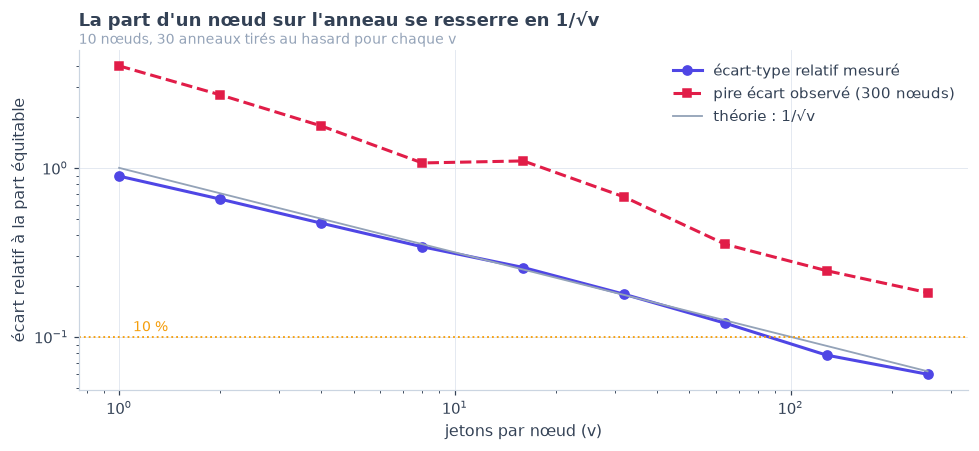

In [7]:
vs = [1, 2, 4, 8, 16, 32, 64, 128, 256]
ecarts = []
for v in vs:
    rel = []
    for seed in range(30):
        r = P.HashRing([f"n{i}" for i in range(10)], vnodes=v, seed=seed)
        rel += list(np.array(list(r.ownership().values())) * 10 - 1)
    ecarts.append((np.std(rel), np.max(np.abs(rel))))
ecarts = np.array(ecarts)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(vs, ecarts[:, 0], "o-", color=INDIGO, label="écart-type relatif mesuré")
ax.loglog(vs, ecarts[:, 1], "s--", color=ROSE, ms=5, label="pire écart observé (300 nœuds)")
ax.loglog(vs, 1 / np.sqrt(vs), color=GRAY, lw=1.2, label="théorie : 1/√v")
ax.axhline(0.1, color=AMBER, ls=":", lw=1.2)
ax.text(1.1, 0.108, "10 %", color=AMBER, fontsize=9)
ax.set_xlabel("jetons par nœud (v)"); ax.set_ylabel("écart relatif à la part équitable")
ax.set_title("La part d'un nœud sur l'anneau se resserre en 1/√v")
subtitle(ax, "10 nœuds, 30 anneaux tirés au hasard pour chaque v")
ax.legend()
plt.tight_layout(); plt.show()

Le tableau retrouve $N/(N+1)$ pour le modulo, alors que le nombre fixe de
partitions et l'anneau déplacent à peu près l'optimum $1/(N+1)$ (le nombre fixe exactement à
l'arrondi près, puisque 840 est divisible par 3, 4, 5, 6, 10, 20 et 21 ; l'anneau à
quelques points près, parce que la part du nouveau nœud est elle-même aléatoire). La
figure confirme la loi en $1/\sqrt{v}$ : l'écart-type mesuré passe sous 10 % vers
$v = 100$. Le pire nœud, lui, s'écarte environ trois fois plus que l'écart-type : avec
16 jetons, le pire des 300 nœuds tirés porte encore environ deux fois sa part.

> **À retenir.** Le modulo déplace presque tout ($N/(N+1)$), les schémas conçus pour le
> rééquilibrage déplacent le minimum ($1/(N+1)$). Sur un anneau à jetons aléatoires,
> l'équilibre s'achète par le nombre de jetons : l'écart relatif vaut $1/\sqrt{v}$.

## Exercice 6.4 : combien de partitions fixes pour un jeu de données qui croît ?

**Énoncé.** Une base démarre avec 2 To et devrait atteindre 200 To en cinq ans
(croissance exponentielle régulière). L'équipe d'exploitation juge qu'une partition
se gère bien entre 10 et 50 Go : en dessous, le surcoût fixe par
partition (fichiers, métadonnées, mémoire, coordination) domine ; au-dessus, déplacer
ou reconstruire une partition devient long. Le nombre de partitions est fixé à la
création.

1. Quel nombre de partitions respecte la borne haute dans cinq ans ? Quelle taille
   ont-elles au départ ? Peut-on rester dans la fourchette pendant toute la période ?
2. Le cluster passera de 6 à environ 120 nœuds. Pourquoi préférer 5 040 à 4 096 ?
3. Alternative : démarrer avec un nombre de partitions adapté à 2 To et repartitionner
   (scinder chaque partition en deux) quand la borne haute est atteinte. Combien de
   scissions générales en cinq ans, et quel volume réécrit au total ?

**Rappels.** Avec un nombre fixe de partitions, la taille de chacune est proportionnelle
au volume total ; un mauvais choix initial impose un repartitionnement coûteux (cours 2,
section *Fixed number of partitions*).

**Solution.**

*1.* Borne haute à 200 To : $200\,000 / 50 = 4\,000$ partitions au moins. Au départ,
$2\,000 / 4\,000 = 0{,}5$ Go chacune, vingt fois sous la borne basse. La fourchette
10-50 Go ne couvre qu'un facteur 5 alors que les données croissent d'un facteur 100 :
**aucun nombre fixe ne convient sur toute la période**. Avec une croissance de
$100^{1/5} \approx 2{,}5$ par an, la taille entre dans la fourchette au bout de
$\ln(20)/\ln(2{,}51) \approx 3{,}3$ ans : on accepte trois ans de partitions trop petites
(le surcoût fixe est le moindre mal).

*2.* On veut répartir les partitions équitablement quel que soit le nombre de nœuds :
5 040 = 2⁴·3²·5·7 a 60 diviseurs (6, 7, 8, 9, 10, 12, 14, 15, 16, 18, 20, 21, 24, 28,
30... 120), alors que 4 096 n'a que 13 diviseurs, tous des puissances de deux : avec 6,
10 ou 120 nœuds, certains nœuds portent une partition de plus que d'autres, là où 5 040
se répartit exactement (100 ne divise pas 5 040 non plus : 50 ou 51 par nœud). Avec 4 096
partitions sur 100 nœuds, c'est 41 contre 40, soit 2,5 % d'écart ; sur 120 nœuds, 35
contre 34 (3 %). L'écart est modeste avec autant de partitions : il devient sensible
quand il y en a peu par nœud.

*3.* 2 To / 50 Go = 40 partitions au départ (pleines) ; chaque scission générale double
leur nombre. Il en faut $\lceil \log_2 100 \rceil = 7$ pour suivre (40 × 2⁷ = 5 120). Une
scission réécrit tout le volume présent à ce moment-là : environ 4, 8, 16... 128 To,
soit à peu près **250 To réécrits** en cinq ans, plus que la taille finale. C'est le prix
de partitions toujours bien dimensionnées ; les systèmes à partitionnement dynamique
étalent ce coût en scindant chaque partition au fil de l'eau plutôt que toutes à la
fois.

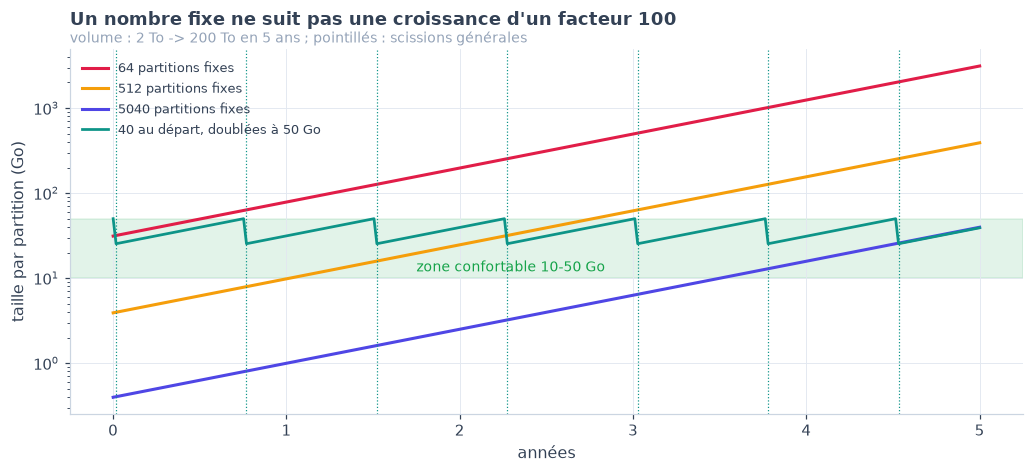

5 040 : taille initiale 0.40 Go, entrée dans la zone après 3.3 ans
scissions générales : 7, volume réécrit : 258 To
diviseurs : 5040 -> 60, 4096 -> 13, 840 -> 32
  6 nœuds : 4096 -> 682..683 par nœud ; 5040 -> 840..840
 10 nœuds : 4096 -> 409..410 par nœud ; 5040 -> 504..504
100 nœuds : 4096 -> 40..41 par nœud ; 5040 -> 50..51
120 nœuds : 4096 -> 34..35 par nœud ; 5040 -> 42..42


In [8]:
ans = np.linspace(0, 5, 300)
volume = 2_000 * 100 ** (ans / 5)          # Go

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.axhspan(10, 50, color=GREEN, alpha=0.12)
ax.text(1.75, 12, "zone confortable 10-50 Go", color=GREEN, fontsize=9)
for n, c in [(64, ROSE), (512, AMBER), (5040, INDIGO)]:
    ax.plot(ans, volume / n, color=c, label=f"{n} partitions fixes")
# repartitionnement : on double quand on dépasse 50 Go
n_dyn, taille, scissions, reecrit = 40, [], [], 0.0
for a, v in zip(ans, volume):
    if v / n_dyn > 50:
        reecrit += v
        n_dyn *= 2
        scissions.append(a)
    taille.append(v / n_dyn)
ax.plot(ans, taille, color=TEAL, lw=1.8, label="40 au départ, doublées à 50 Go")
for a in scissions:
    ax.axvline(a, color=TEAL, ls=":", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("années"); ax.set_ylabel("taille par partition (Go)")
ax.set_title("Un nombre fixe ne suit pas une croissance d'un facteur 100")
subtitle(ax, "volume : 2 To -> 200 To en 5 ans ; pointillés : scissions générales")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

entree = math.log(20) / math.log(100 ** 0.2)
print(f"5 040 : taille initiale {2000 / 5040:.2f} Go, entrée dans la zone après {entree:.1f} ans")
print(f"scissions générales : {len(scissions)}, volume réécrit : {reecrit / 1000:.0f} To")
div = lambda n: sum(1 for d in range(1, n + 1) if n % d == 0)
print(f"diviseurs : 5040 -> {div(5040)}, 4096 -> {div(4096)}, 840 -> {div(840)}")
for nodes in [6, 10, 100, 120]:
    print(f"{nodes:>3} nœuds : 4096 -> {4096 // nodes}..{-(-4096 // nodes)} par nœud ; "
          f"5040 -> {5040 // nodes}..{-(-5040 // nodes)}")

La simulation retrouve les sept scissions générales et un volume réécrit cumulé du même
ordre que l'estimation (un peu au-dessus de 200 To, car chaque scission a lieu dès que
le seuil est franchi). La figure montre le dilemme : la courbe des 5 040
partitions n'entre dans la zone confortable qu'au bout de trois ans et quelques, et
une valeur plus faible (512, 64) en sort par le haut bien avant la fin.

> **À retenir.** Un nombre fixe de partitions suppose de connaître l'ordre de grandeur
> final des données. On le choisit pour la taille cible (borne haute), en acceptant des
> partitions trop petites au début, et riche en diviseurs pour s'adapter à tout nombre
> de nœuds. Si la croissance est imprévisible, le partitionnement dynamique est plus
> adapté.